In [5]:
# ============================================================
# CELL 1 — Imports and configuration
# ============================================================
# Standard library
import sys
import os
from pathlib import Path
import datetime as dt

# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

# HTTP requests
import requests

# Display settings
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.style.use("seaborn-v0_8-darkgrid")

# ── Path setup ──────────────────────────────────────────────
# Navigate from notebooks/ up to project root, then import config
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import config

# ── Constants ──────────────────────────────────────────────
API_KEY = config.EIA_API_KEY
BASE_URL = "https://api.eia.gov/v2"
YEARS_HISTORY = 5 # how many years of weekly data to pull
CHART_DIR = PROJECT_ROOT / "charts"
DATA_DIR = PROJECT_ROOT / "data"

# ── Date ranges ───────────────────────────────────────────────
# Two separate windows for two distinct analytical purposes:
#   YEARS_HISTORY   : seasonal range chart (recent regime)
#   YEARS_PERCENTILE: percentile rank (longer history)
YEARS_HISTORY    = 5    # for seasonal band on chart
YEARS_PERCENTILE = 10   # for percentile rank calculation

END_DATE          = dt.date.today()
START_DATE        = END_DATE - dt.timedelta(
    days=365 * YEARS_HISTORY + 30
)
START_DATE_PCTILE = END_DATE - dt.timedelta(
    days=365 * YEARS_PERCENTILE + 30
)


print("=" * 55)
print( "EIA Inventory Tracker - configuration loaded")
print("=" * 55)
print(f"Project root: {PROJECT_ROOT}")
print(f"API key: {'loaded' if API_KEY else 'MISSING'}")
print(f"Date range: {START_DATE} -> {END_DATE}")
print(f"History: {YEARS_HISTORY} years of weekly data")
print(f"Percentile History: {YEARS_PERCENTILE} years of weekly data for percentile calculations")
print("=" * 55)

EIA Inventory Tracker - configuration loaded
Project root: c:\Users\mackt\Python Projects\oil_gas_tools
API key: loaded
Date range: 2021-09-11 -> 2026-10-10
History: 5 years of weekly data
Percentile History: 10 years of weekly data for percentile calculations


In [2]:
# ============================================================
# CELL 2 — EIA API fetch function
# ============================================================
# This is a resuable function to be called in every tool we build (in this project)
# It handles teh HTTP request, checks for errors, and returns
# a clean pandas dataframe every time

# EIA API v2 structure:
# Base URL: https://api.eia.gov/v2
# Series: /petroleum/stoc/wstk/data/
# Key params: 
# frequency = weekly
# facets: duoarea (location) + product (commodity) + process (type)
# start/end = YYYY-MM-DD
# length = max rows per page (up to 5000)

def fetch_eia_series(
    route: str,
    facets: dict,
    start: str,
    end: str,
    api_key: str,
    frequency: str = "weekly",
    value_col: str = "value",
    max_rows: int = 5000,
) -> pd.DataFrame:
    """
    Fetch a time series from the EIA API v2 and return a DataFrame.

    Parameters
    ----------
    route: API route after base url, eg: '/petroleum/stoc/wstk/data/'
    facets: dict of filter facets, eg: {'duoarea': ['NUS'], 'product': ['EPCO']}
    start: start date string 'YYYY-MM-DD'
    end: end date string 'YYYY-MM-DD'
    api_key: my EIA API key
    frequency: data frequency - 'weekly', 'monthly', 'annual'
    value_col: what to name the value column in the output DataFrame
    max_rows: maximum rows to return per request (EIA cap is 5000)

    Returns
    -------
    pd.DataFrame with columns: date, {value_col}
    Sorted ascending by date, with date as datetime64
    """

    # ── Build request parameters ─────────────────────────────
    params = { 
        "api_key": api_key,
        "frequency": frequency,
        "data[0]": "value",
        "start": start,
        "end": end,
        "sort[0][column]": "period",
        "sort[0][direction]": "asc",
        "length": max_rows,
    }

    # Add facets - EIA v2 expects facets as repeated params
    # eg: facets[duoara][]=NUS&facets[product][]=EPCO
    for facet_name, facet_values in facets.items():
        for i, val in enumerate(facet_values):
            params[f"facets[{facet_name}][]"] = val

    url = f"{BASE_URL}{route}"

    # ── Make the request ─────────────────────────────────────
    try:
        response = requests.get(url, params=params, timeout=30)
        response.raise_for_status() # raises on 4xx / 5xx
    except requests.exceptions.Timeout:
        raise RuntimeError(
        "EIA API request timed out.\n"
        "This usually means the API is temporarily down for maintenance.\n"
        "Check https://api.eia.gov in a browser — if it doesn't load,\n"
        "wait 30–60 minutes and try again."
    )
    except requests.exceptions.HTTPError as e:
        raise RuntimeError(f"EIA API HTTP error: {e}\nURL: {response.url}")
    except requests.exceptions.RequestException as e:
        raise RuntimeError(f"EIA API request failed: {e}")

    # ── Parse response ───────────────────────────────────────
    payload = response.json()

    # Check for API-level errors in the response body
    if "error" in payload:
        raise RuntimeError(f"EIA API returned an error: {payload['error']}")

    data = payload.get("response", {}).get("data", [])

    if not data:
        raise ValueError(
            f"EIA API returned no data for this request.\n"
            f"Route: {route}\nFacets: {facets}\n"
            f"Date range: {start} -> {end}\n"
            f"Check that your facet codes are correct."
        )

    # ── Build DataFrame ──────────────────────────────────────
    df = pd.DataFrame(data)

    # 'period' is the date field in EIA v2
    df["date"] = pd.to_datetime(df["period"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df = df[["date", "value"]].copy()
    df = df.rename(columns={"value": value_col})
    df.sort_values("date").reset_index(drop=True)

    # Drop any rows where value is NaN
    n_before = len(df)
    df = df.dropna(subset=[value_col])
    n_dropped = n_before - len(df)

    if n_dropped > 0:
        print(f"!! Dropped {n_dropped} rows with missing values.")

    return df

# ── Quick smoke test ─────────────────────────────────────────
# Confirm the function is defined and callable
print("=" * 55)
print("Cell 2 Loaded - fetch_eia_series() ready")
print(f"Base URL: {BASE_URL}")
print(f"Timeout: 30 seconds per request")
print(f"Max rows: 5,000 per request")
print("=" * 55)

Cell 2 Loaded - fetch_eia_series() ready
Base URL: https://api.eia.gov/v2
Timeout: 30 seconds per request
Max rows: 5,000 per request


In [3]:
# ============================================================
# CELL 3 — Pull inventory data from EIA
# ============================================================
# EIA series we need:
#
#   US Total Crude Stocks
#     route   : /petroleum/stoc/wstk/data/
#     duoarea : NUS   (N = national, US)
#     product : EPC0  (crude oil)
#     process : SAX - Ending Stocks Excluding SPR [Strategic Petroleum Reserve - US Govt stockpile unavailable for commercial use]
#
#   Cushing, OK Crude Stocks
#     route   : /petroleum/stoc/wstk/data/
#     duoarea : YCUOK  (Cushing, Oklahoma)
#     product : EPC0
#     process : SAX - Ending Stocks Excluding SPR [Strategic Petroleum Reserve - US Govt stockpile unavailable for commercial use]
#
# Units: thousand barrels (Mbbl)
# We will convert to million barrels (MMbbl) for readability
# ─────────────────────────────────────────────────────────────

ROUTE = "/petroleum/stoc/wstk/data/"
START = START_DATE.strftime("%Y-%m-%d")
END = END_DATE.strftime("%Y-%m-%d")

print("Fetching data from EIA API...")
print(f"  Date range : {START} → {END}\n")

# ── US total crude stocks ────────────────────────────────────
print("  [1/2] US total crude stocks...", end=" ")

df_us = fetch_eia_series(
    route     = ROUTE,
    facets    = {
        "duoarea" : ["NUS"],
        "product" : ["EPC0"],
        "process" : ["SAX"],   # <- add this line: excluding SPR
    },
    start     = START,
    end       = END,
    api_key   = API_KEY,
    value_col = "us_crude_stocks",
)

df_us["us_crude_stocks"] = df_us["us_crude_stocks"] / 1_000
print(f"OK  ({len(df_us)} weeks)")

# ── Cushing stocks ───────────────────────────────────────────
print("  [2/2] Cushing, OK crude stocks...", end=" ")

df_cush = fetch_eia_series(
    route     = ROUTE,
    facets    = {
        "duoarea" : ["YCUOK"],
        "product" : ["EPC0"],
        "process" : ["SAX"],   # <- Cushing uses SAE (no SPR stored there)
    },
    start     = START,
    end       = END,
    api_key   = API_KEY,
    value_col = "cushing_stocks",
)

df_cush["cushing_stocks"] = df_cush["cushing_stocks"] / 1_000
print(f"OK  ({len(df_cush)} weeks)")


# ── Merge into single DataFrame ──────────────────────────────
df = pd.merge(df_us, df_cush, on="date", how="inner")
df = df.sort_values("date").reset_index(drop=True)

# ── Add calendar columns we'll need for seasonal analysis ───
df["year"] = df["date"].dt.year
df["week"] = df["date"].dt.isocalendar().week.astype(int)
df["month"] = df["date"].dt.month

# ── Pull longer history for percentile calculation ────────────
# Separate from seasonal range — we want more data points
# per week to get a meaningful continuous percentile rank.
# EIA crude inventory goes back to 1982 — 10yr window gives
# 9 prior-year data points per week (vs 4 in 5yr window).
print("Pulling extended history for percentile calculation...")

START_PCTILE = START_DATE_PCTILE.strftime("%Y-%m-%d")

df_us_pctile = fetch_eia_series(
    route     = "/petroleum/stoc/wstk/data/",
    facets    = {"duoarea": ["NUS"],
                 "product" : ["EPC0"],
                 "process" : ["SAX"]},
    start     = START_PCTILE,
    end       = END,
    api_key   = API_KEY,
    value_col = "us_crude_stocks",
)
df_us_pctile["year"]    = df_us_pctile["date"].dt.year
df_us_pctile["week"]    = (df_us_pctile["date"]
                           .dt.isocalendar().week.astype(int))
df_us_pctile["week_id"] = df_us_pctile["week"].clip(upper=52)

df_cush_pctile = fetch_eia_series(
    route     = "/petroleum/stoc/wstk/data/",
    facets    = {"duoarea": ["YCUOK"],
                 "product" : ["EPC0"],
                 "process" : ["SAX"]},
    start     = START_PCTILE,
    end       = END,
    api_key   = API_KEY,
    value_col = "cushing_stocks",
)
df_cush_pctile["year"]    = df_cush_pctile["date"].dt.year
df_cush_pctile["week"]    = (df_cush_pctile["date"]
                             .dt.isocalendar().week.astype(int))
df_cush_pctile["week_id"] = df_cush_pctile["week"].clip(upper=52)

# Historical only (exclude current year)
CURRENT_YEAR = df["date"].dt.year.max()
df_us_pctile_hist = df_us_pctile[
    df_us_pctile["year"] < CURRENT_YEAR
].copy()
df_cush_pctile_hist = df_cush_pctile[
    df_cush_pctile["year"] < CURRENT_YEAR
].copy()


# ── Preview ──────────────────────────────────────────────────
print("\n" + "=" * 55)
print("Data pull complete")
print("=" * 55)
print(f"Rows         : {len(df)} weekly observations")
print(f"Date range   : {df['date'].min().date()}  →  {df['date'].max().date()}")
print(f"US stocks    : {df['us_crude_stocks'].min():.1f} – "
      f"{df['us_crude_stocks'].max():.1f} MMbbl")
print(f"Cushing      : {df['cushing_stocks'].min():.1f} – "
      f"{df['cushing_stocks'].max():.1f} MMbbl")
print("=" * 55)
print()
print(df.tail(8).to_string(index=False))
print()
print()
print(f"  US percentile history  : "
      f"{len(df_us_pctile_hist)} weeks "
      f"({df_us_pctile_hist['year'].min()}-"
      f"{df_us_pctile_hist['year'].max()})")
print(f"  Cushing percentile hist: "
      f"{len(df_cush_pctile_hist)} weeks "
      f"({df_cush_pctile_hist['year'].min()}-"
      f"{df_cush_pctile_hist['year'].max()})")

Fetching data from EIA API...
  Date range : 2021-09-11 → 2026-10-10

  [1/2] US total crude stocks... OK  (264 weeks)
  [2/2] Cushing, OK crude stocks... OK  (264 weeks)
Pulling extended history for percentile calculation...

Data pull complete
Rows         : 264 weekly observations
Date range   : 2021-09-17  →  2026-10-02
US stocks    : 404.5 – 481.2 MMbbl
Cushing      : 18.6 – 43.2 MMbbl

      date  us_crude_stocks  cushing_stocks  year  week  month
2026-08-14          428.815          21.252  2026    33      8
2026-08-21          428.910          22.428  2026    34      8
2026-08-28          424.460          22.508  2026    35      8
2026-09-04          424.069          21.824  2026    36      9
2026-09-11          423.429          21.482  2026    37      9
2026-09-18          426.398          23.748  2026    38      9
2026-09-25          427.320          24.301  2026    39      9
2026-10-02          424.134          24.745  2026    40     10


  US percentile history  : 485 weeks

In [4]:
# ============================================================
# CELL 4 — Clean and validate the data
# ============================================================
# At this point df contains 265 weekly observations with both inventory series merged. This cell:
#   1. Checks for and handles any duplicate dates
#   2. Checks for gaps in the weekly sequence
#   3. Validates value ranges are physically plausible
#   4. Adds a week_id column for clean seasonal grouping
#   5. Splits into current year vs historic for plotting
# ─────────────────────────────────────────────────────────────

print("Running data validation...")
print()

## ── 1. Check for duplicate dates ────────────────────────────
dupes = df[df.duplicated(subset=["date"], keep = False)]
if len(dupes) > 0:
    print(f" !! WARNING: {len(dupes)} duplicate dates found - dropping extras")
    df = df.drop_duplicates(subset=["date"], keep="last")
else:
    print("No duplicate dates")

# ── 2. Check for gaps in weekly sequence ────────────────────
df_sorted = df.sort_values("date").reset_index(drop=True)
date_diffs = df_sorted["date"].diff().dropna()
expected = pd.Timedelta(days=7)
gaps = date_diffs[date_diffs > expected + pd.Timedelta(days=3)]

if len(gaps) > 0:
    print(f" !! WARNING: {len(gaps)} gaps in weekly sequence: ")
    for idx, gap in gaps.items():
        print(f"    {df_sorted.loc[idx-1, 'date'].date()} -> "
              f"{df_sorted.loc[idx, 'date'].date()} " 
              f"({gap.days} days)")
else:
    print("No gaps in weekly sequence")

# ── 3. Validate value ranges ─────────────────────────────────
# US crude stocks: physically plausible range 300-700 MMbbl 
# Cushing stocks: physically plausible range: 10-100 MMbbl

checks = [ 
    ("us_crude_stocks", 300, 700, "MMbbl"),
    ("cushing_stocks", 10, 100, "MMbbl"),
]

for col, lo, hi, unit in checks:
    out_of_range = df[(df[col] < lo) | (df[col] > hi)]
    if len(out_of_range) > 0:
        print(f"!! WARNING: {len(out_of_range)} rows outside " 
              f"plausible ra nge [{lo} - {hi}] in {col}")
        print(out_of_range[["date", col]])
    else:
        print(f" {col}: all values in plausible range " 
              f"[{lo} - {hi} {unit}]")
        
# ── 4. Add week_id for seasonal grouping ────────────────────
# ISO week numbers run 1-52/53 and can be slightly inconsistent
# at year boundaries. We use a simple 1-52 cap for clean grouping.

df["week_id"] = df["week"].clip(upper=52)

# ── 5. Split current year vs historical ──────────────────────
CURRENT_YEAR = df["date"].dt.year.max()
HISTORY_YEAR = CURRENT_YEAR - 1 # last complete year for reference line

df_current = df[df["year"] == CURRENT_YEAR].copy()
df_history = df[df["year"] < CURRENT_YEAR].copy()

print()
print("=" * 55)
print("Validation complete")
print("=" * 55)
print(f"Total rows: {len(df)}")
print(f"Current year: {CURRENT_YEAR} "
      f"({len(df_current)} weeks so far)")
print(f"Historical years: {df_history['year'].min()} - "
      f"{HISTORY_YEAR} "
      f"({len(df_history)} weeks)")
print(f"Week IDs: {df['week_id'].min()} - "
      f"{df['week_id'].max()}")
print("=" * 55)

Running data validation...

No duplicate dates
No gaps in weekly sequence
 us_crude_stocks: all values in plausible range [300 - 700 MMbbl]
 cushing_stocks: all values in plausible range [10 - 100 MMbbl]

Validation complete
Total rows: 264
Current year: 2026 (40 weeks so far)
Historical years: 2021 - 2025 (224 weeks)
Week IDs: 1 - 52


In [5]:
# ============================================================
# CELL 5 — Build the 5-year seasonal range
# ============================================================
# For each week of the year (1-52), we calculate across all
# historical years:
# - mean: the average inventory level for that week
# - min: the lowest inventory seen in that week
# - max: the highest inventory seen in that week
# - prior_yr: the last complete year's value for that week

# This gives us the season envelope - the shaded band you
# see on every professional crude inventory chart.

# We build this for both US total and Cushing separately.

def build_seasonal_range(df_hist: pd.DataFrame,
                         value_col: str) -> pd.DataFrame:
    """
    Given a historical DataFrame (all years except current), 
    return a DataFrame indexed by week_id (1-52) with columns:
    mean, min, max, std, and prior_yr (most recent full year).
    """

    prior_year = df_hist["year"].max()

    # Group by week_id across all historical years
    grouped = df_hist.groupby("week_id")[value_col].agg(
        mean = "mean",
        min = "min",
        max = "max",
        std = "std",
    ).reset_index()

    # Pull prior year as a separate reference line
    df_prior = (
        df_hist[df_hist["year"] == prior_year]
        [["week_id", value_col]]
        .rename(columns={value_col: "prior_yr"})
    )

    seasonal = pd.merge(grouped, df_prior, on="week_id", how="left")
    seasonal = seasonal.sort_values("week_id").reset_index(drop=True)

    return seasonal, prior_year

# ── Build seasonal ranges ────────────────────────────────────
seasonal_us, prior_yr_us = build_seasonal_range(
    df_history, "us_crude_stocks"
)

seasonal_cush, prior_yr_cush = build_seasonal_range(
    df_history, "cushing_stocks"
)

# ── Merge current year onto seasonal range ───────────────────
# We'll need this for the inventory signal in Cell 7

df_current_us = (
    df_current[["week_id", "date", "us_crude_stocks"]]
    .merge(seasonal_us, on="week_id", how="left")
)

df_current_cush = (
    df_current[["week_id", "date", "cushing_stocks"]]
    .merge(seasonal_cush, on="week_id", how="left")
)

# ── Calculate deviation from mean ───────────────────────────
# How far is the current level from the seasonal average?
# Expressed in MMbbl and in standard deviations
# This is also called the Z-Score (used in Cell 7)

df_current_us["deviation_mmbbl"] = (
    df_current_us["us_crude_stocks"] - df_current_us["mean"]
)

df_current_us["deviation_std"] = (
    df_current_us["deviation_mmbbl"] / df_current_us["std"]
)

df_current_cush["deviation_mmbbl"] = (
    df_current_cush["cushing_stocks"] - df_current_cush["mean"]
)

df_current_cush["deviation_std"] = (
    df_current_cush["deviation_mmbbl"] / df_current_cush["std"]
)

# ── Preview ──────────────────────────────────────────────────
print("=" * 55)
print("Seasonal ranges built")
print("=" * 55)
print(f"Historical window: {df_history['year'].min()} - "
      f"{df_history['year'].max()}")
print(f"Prior year: {prior_yr_us}")
print(f"Weeks in range: {len(seasonal_us)}")
print()
cols_to_show = ["date", "us_crude_stocks", "mean", "deviation_mmbbl", "deviation_std"]
recent = df_current_us[cols_to_show].tail(6).copy()
recent["date"] = recent["date"].dt.strftime("%Y-%m-%d")
recent.columns = ["Date", "Actual", "Avg", "Dev (MMbbl)", "Dev(sigma)"]
print(recent.to_string(index=False, float_format=lambda x: f"{x:,.1f}"))
print()

# Most recent single reading summary
latest_us = df_current_us.iloc[-1]
latest_cush = df_current_cush.iloc[-1]

print("=" * 55)
print(f"Latest US stocks: {latest_us['us_crude_stocks']:.1f} MMbbl")
print(f"5yr seasonal avg: {latest_us['mean']:.1f} MMbbl")
print(f"Deviation: {latest_us['deviation_mmbbl']:+.1f} MMbbl "
      f"({latest_us['deviation_std']:+.2f}σ)")
print()
print(f"Latest Cushing: {latest_cush['cushing_stocks']:.1f} MMbbl")
print(f"5yr seasonal avg: {latest_cush['mean']:.1f} MMbbl")
print(f"Deviation: {latest_cush['deviation_mmbbl']:+.1f} MMbbl "
      f"({latest_cush['deviation_std']:+.2f}σ)")
print("=" * 55)


Seasonal ranges built
Historical window: 2021 - 2025
Prior year: 2025
Weeks in range: 52

      Date  Actual   Avg  Dev (MMbbl)  Dev(sigma)
2026-08-28   424.5 420.7          3.7         0.8
2026-09-04   424.1 423.5          0.6         0.1
2026-09-11   423.4 419.2          4.2         0.6
2026-09-18   426.4 418.6          7.8         1.1
2026-09-25   427.3 419.5          7.8         1.3
2026-10-02   424.1 426.7         -2.5        -0.3

Latest US stocks: 424.1 MMbbl
5yr seasonal avg: 426.7 MMbbl
Deviation: -2.5 MMbbl (-0.34σ)

Latest Cushing: 24.7 MMbbl
5yr seasonal avg: 25.7 MMbbl
Deviation: -1.0 MMbbl (-0.21σ)


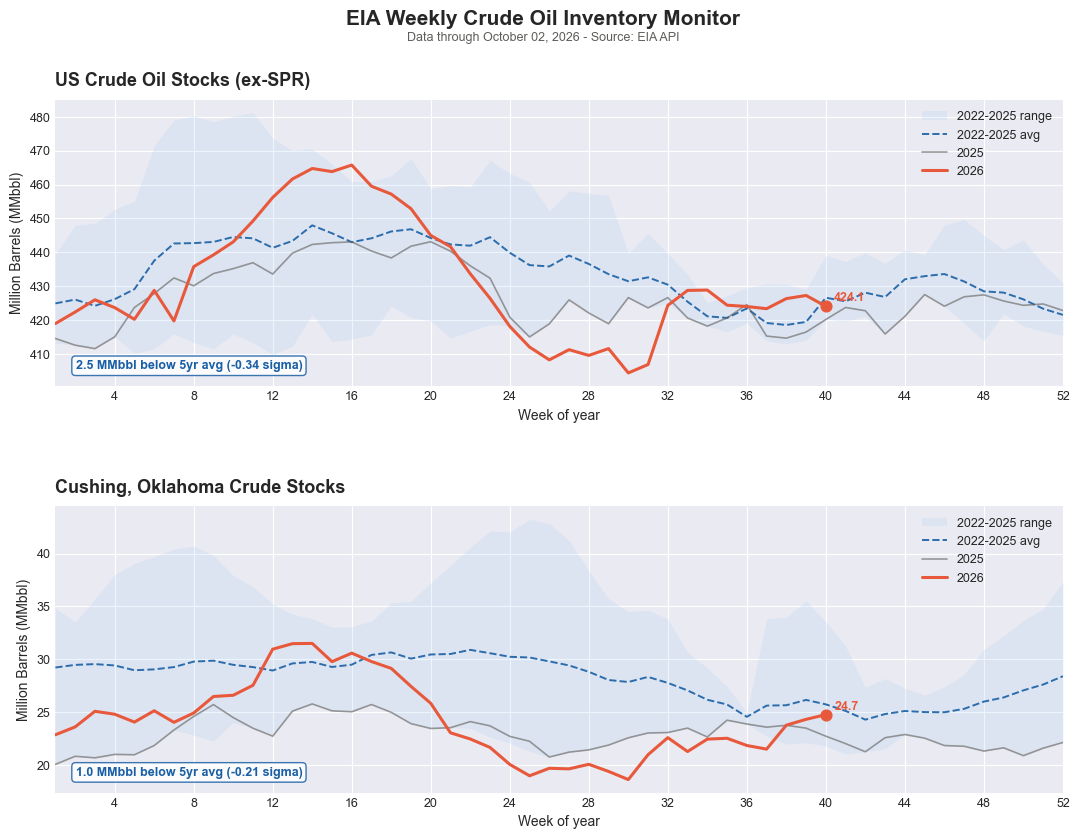


  Chart saved → c:\Users\mackt\Python Projects\oil_gas_tools\charts\inventory_monitor_October_02_2026.png


In [6]:
# ============================================================
# CELL 6 — Plot inventory vs 5-year seasonal range
# ============================================================
# Two-panel chart:
# Top: US total crude stocks (ex-SPR)
# Bottom: Cushing, Oklahoma stocks

# Each panel shows:
# Shaded band: 5yr min-max range (the envelope)
# Dashed line: 5yr seasonal mean
# Solid line: prior year (2025)
# Bold line: current year (2026)
# Dot: most recent data point
# ─────────────────────────────────────────────────────────────
# We start by writing a function that will be called to plot our data

def plot_inventory_panel(
        ax,
        seasonal: pd.DataFrame,
        df_curr: pd.DataFrame,
        value_col: str,
        title: str,
        ylabel: str,
        current_year: int,
        prior_year: int,
        color_current: str ="#E8593C",
        color_prior: str = "#5F5E5A",
        color_mean: str = "#185FA5",
        color_band: str = "#B5D4F4",
):
    """
    Plot one inventory panel onto the given Axes object.
    Resuable for US total and Cushing panels.
    """
    weeks = seasonal["week_id"].values

    # ── Shaded min–max band ──────────────────────────────────
    ax.fill_between(
        weeks,
        seasonal["min"],
        seasonal["max"],
        alpha = 0.25,
        color = color_band,
        label = f"{prior_year-3}-{prior_year} range",
        linewidth = 0,
    )
    # ── Seasonal mean line ───────────────────────────────────
    ax.plot(
        weeks,
        seasonal["mean"],
        color = color_mean,
        linewidth = 1.4,
        linestyle = "--",
        alpha = 0.9,
        label = f"{prior_year-3}-{prior_year} avg",
        zorder = 3,
    )
    # ── Prior year line ──────────────────────────────────────
    ax.plot(
        weeks,
        seasonal["prior_yr"],
        color = color_prior,
        linewidth = 1.2,
        linestyle = "-",
        alpha = 0.6,
        label = str(prior_year),
        zorder = 4,
    )
    # ── Current year line ────────────────────────────────────
    ax.plot(
        df_curr["week_id"],
        df_curr[value_col],
        color = color_current,
        linewidth = 2.2,
        linestyle = "-",
        label = str(current_year),
        zorder = 5,
    )

    # ── Most recent data point dot ───────────────────────────
    latest = df_curr.iloc[-1]
    ax.scatter(
        latest["week_id"],
        latest[value_col],
        color = color_current,
        s = 60,
        zorder = 6,
    )
    # ── Annotate latest value ────────────────────────────────
    ax.annotate(
        f"{latest[value_col]:.1f}",
        xy = (latest["week_id"], latest[value_col]),
        xytext = (6, 4),
        textcoords = "offset points",
        fontsize = 9,
        color = color_current,
        fontweight = "bold",
    )
    # ── Axes formatting ──────────────────────────────────────
    ax.set_title(title, fontsize=13, fontweight="bold",
                 pad=10, loc="left")
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xlabel("Week of year", fontsize=10)
    ax.set_xlim(1, 52)
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
    )
    ax.xaxis.set_major_locator(mticker.MultipleLocator(4))
    ax.xaxis.set_minor_locator(mticker.MultipleLocator(1))
    ax.tick_params(axis="both", labelsize=9)
    ax.legend(fontsize=9, loc="upper right",
              framealpha=0.85, edgecolor="none")
    
    # ── Deviation annotation box ─────────────────────────────
    dev_mmbbl = latest[value_col] - latest["mean"]
    dev_std = dev_mmbbl / latest["std"]
    direction = "above" if dev_mmbbl >= 0 else "below"
    color_box = "#c04828" if dev_mmbbl >= 0 else "#185FA5"

    ax.text(
        0.02, 0.06,
        f"{abs(dev_mmbbl):.1f} MMbbl {direction} 5yr avg "
        f"({dev_std:+.2f} sigma)",
        transform = ax.transAxes,
        fontsize = 9,
        color = color_box,
        fontweight = "bold",
        bbox = dict(boxstyle="round,pad=0.3",
                    facecolor="white",
                    edgecolor=color_box,
                    alpha=0.85),
    )
    
    return ax

# The above function does all kinds of plot formatting for us - lots of settings naturally
# Read some matplotlib ax documentation when you have time to familiarize with these various features

# ── Build the figure ─────────────────────────────────────────
fig, axes = plt.subplots(
    2,1,
    figsize = (13, 9),
    sharex = False,
    gridspec_kw = {"hspace": 0.42},
)

# Top panel - US total crude
plot_inventory_panel(
    ax = axes[0],
    seasonal = seasonal_us,
    df_curr = df_current_us,
    value_col = "us_crude_stocks",
    title = "US Crude Oil Stocks (ex-SPR)",
    ylabel = "Million Barrels (MMbbl)",
    current_year = CURRENT_YEAR,
    prior_year = prior_yr_us,
)

# Bottom panel - Cushing, Oklahoma
plot_inventory_panel(
    ax = axes[1],
    seasonal = seasonal_cush,
    df_curr = df_current_cush,
    value_col = "cushing_stocks",
    title = "Cushing, Oklahoma Crude Stocks",
    ylabel = "Million Barrels (MMbbl)",
    current_year = CURRENT_YEAR,
    prior_year = prior_yr_cush,
)

# ── Figure-level annotations ─────────────────────────────────
latest_date = df_current["date"].max().strftime("%B %d, %Y")
fig.suptitle(
    f"EIA Weekly Crude Oil Inventory Monitor",
    fontsize = 15,
    fontweight = "bold",
    y = 0.98,
)

fig.text(
    0.5, 0.945,
    f"Data through {latest_date} - Source: EIA API",
    ha = "center",
    fontsize = 9,
    color = "#5F5E5A",
)


# ── Save and show ────────────────────────────────────────────
chart_path = CHART_DIR / f"inventory_monitor_{latest_date.replace(' ','_').replace(',','')}.png"
plt.savefig(chart_path, dpi=150, bbox_inches="tight",
            facecolor="white")
plt.show()

print(f"\n  Chart saved → {chart_path}")

In [7]:
# ============================================================
# CELL 7 — Inventory signal dashboard & plain English summary
# ============================================================

# Combines US and Cushing deviations into a composite signal,
# calculates percentile rank, week-on-week (WoW) change, and prints
# a plain-English paragraph suitable for a morning briefing.
# Note: Z-Scores were calculated in Cell 5 
# ─────────────────────────────────────────────────────────────

# ── Pull latest readings ─────────────────────────────────────
latest_us = df_current_us.iloc[-1]
latest_cush = df_current_cush.iloc[-1]
latest_date = df_current["date"].max().strftime("%B %d, %Y")

# ── Deviations ───────────────────────────────────────────────
us_dev_mmbbl = latest_us["us_crude_stocks"] - latest_us["mean"]
us_dev_std = float(latest_us["deviation_std"])
cush_dev_mmbbl = latest_cush["cushing_stocks"] - latest_cush["mean"]
cush_dev_std = float(latest_cush["deviation_std"])

# ── Signal classifier ────────────────────────────────────────
def classify_signal(z: float) -> tuple[str, str]:
    """
    Convert a z-score into dreiction + strength labels.
    Negative z -> below average -> BULLISH.
    Positive z -> above average -> BEARISH.
    """
    abs_z = abs(z)

    if abs_z < 0.5:
        return "NEUTRAL", ""
    elif abs_z < 1.0:
        direction = "BULLISH" if z < 0 else "BEARISH"
        return direction, "mild"
    elif abs_z < 1.5:
        direction = "BULLISH" if z < 0 else "BEARISH"
        return direction, "moderate"
    elif abs_z < 2.0:
        direction = "BULLISH" if z < 0 else "BEARISH"
        return direction, "strong"
    else:
        direction = "BULLISH" if z < 0 else "BEARISH"
        return direction, "EXTREME"
    
us_direction, us_strength = classify_signal(us_dev_std)
cush_direction, cush_strength = classify_signal(cush_dev_std)

# ── Percentile rank — uses extended 10-year history ──────────
# With 10yr window: 9 prior-year data points per week
# = percentile steps of ~11% (vs 25% with 5yr window)
# Much more meaningful for week-over-week tracking
current_week = int(latest_us["week_id"])

hist_us_week_pctile = df_us_pctile_hist[
    df_us_pctile_hist["week_id"] == current_week
]["us_crude_stocks"].values

hist_cush_week_pctile = df_cush_pctile_hist[
    df_cush_pctile_hist["week_id"] == current_week
]["cushing_stocks"].values

us_pctile = (
    (hist_us_week_pctile < latest_us["us_crude_stocks"]).sum()
    / len(hist_us_week_pctile) * 100
    if len(hist_us_week_pctile) > 0 else float("nan")
)

cush_pctile = (
    (hist_cush_week_pctile < latest_cush["cushing_stocks"]).sum()
    / len(hist_cush_week_pctile) * 100
    if len(hist_cush_week_pctile) > 0 else float("nan")
)

n_us_pts   = len(hist_us_week_pctile)
n_cush_pts = len(hist_cush_week_pctile)

print(f"  Percentile based on {n_us_pts} prior-year observations "
      f"({YEARS_PERCENTILE}yr window)")

# ── Week-on-week change ──────────────────────────────────────
if len(df_current_us) >= 2:
    us_wow = (df_current_us.iloc[-1]["us_crude_stocks"]
              - df_current_us.iloc[-2]["us_crude_stocks"])
    cush_wow = (df_current_cush.iloc[-1]["cushing_stocks"]
                - df_current_cush.iloc[-2]["cushing_stocks"])
else:
    us_wow = cush_wow = float("nan")

# If WoW crude stocks are positive or zero, supply is rising/flat - "build", otherwise, it is falling, a "draw" on supply
wow_dir_us = "build" if us_wow >= 0 else "draw"
wow_dir_cush = "build" if cush_wow >= 0 else "draw"

# ── Year-on-year comparison (your insight from chart reading) ─
# Pull prior year value for the same week
prior_us_week = df_history[
    (df_history["week_id"] == current_week) &
    (df_history["year"] == prior_yr_us)
]["us_crude_stocks"].values

prior_cush_week = df_history[
    (df_history["week_id"] == current_week) &
    (df_history["year"] == prior_yr_us)
]["cushing_stocks"].values

us_yoy = (
    float(latest_us["us_crude_stocks"]) - float(prior_us_week[0])
) if len(prior_us_week) > 0 else float("nan")

cush_yoy = (
    float(latest_cush["cushing_stocks"]) - float(prior_cush_week[0])
) if len(prior_cush_week) > 0 else float("nan")

us_yoy_dir = "above" if us_yoy >= 0 else "below"
cush_yoy_dir = "above" if cush_yoy >= 0 else "below"

# ── Signal dashboard ─────────────────────────────────────────
print("=" * 60)
print("EIA CRUDE INVENTORY SIGNAL DASHBOARD")
print(f"Data through {latest_date}")
print("=" * 60)

print(f"""
  US CRUDE STOCKS (ex-SPR)
  ────────────────────────────────────────────────
  Current level    : {latest_us['us_crude_stocks']:>8.1f} MMbbl
  5yr seasonal avg : {latest_us['mean']:>8.1f} MMbbl
  Deviation        : {us_dev_mmbbl:>+8.1f} MMbbl  ({us_dev_std:+.2f} sigma)
  vs prior year    : {us_yoy:>+8.1f} MMbbl  ({us_yoy_dir} {prior_yr_us})
  Week-on-week     : {us_wow:>+8.1f} MMbbl  ({wow_dir_us})
  Percentile       : {us_pctile:>8.0f}th  (vs same week in history)
  Signal           :  {us_strength} {us_direction}

  CUSHING, OKLAHOMA
  ────────────────────────────────────────────────
  Current level    : {latest_cush['cushing_stocks']:>8.1f} MMbbl
  5yr seasonal avg : {latest_cush['mean']:>8.1f} MMbbl
  Deviation        : {cush_dev_mmbbl:>+8.1f} MMbbl  ({cush_dev_std:+.2f} sigma)
  vs prior year    : {cush_yoy:>+8.1f} MMbbl  ({cush_yoy_dir} {prior_yr_us})
  Week-on-week     : {cush_wow:>+8.1f} MMbbl  ({wow_dir_cush})
  Percentile       : {cush_pctile:>8.0f}th  (vs same week in history)
  Signal           :  {cush_strength} {cush_direction}


  NOTE ON SIGNALS
  {'─' * 48}
  US total and Cushing are reported independently.
  Cushing (~6% of US total) is the WTI delivery
  point — its signal has direct price formation
  relevance beyond what the national total captures.
  Percentile ranks use {YEARS_PERCENTILE}-year history
  ({n_us_pts} data points per week).
""")


# ── Plain English summary ────────────────────────────────────
# ── Plain English Summary ─────────────────────────────────────
us_rel   = "below" if us_dev_mmbbl   < 0 else "above"
cush_rel = "below" if cush_dev_mmbbl < 0 else "above"

# Price bias derived from independent signals
# Cushing weighted more heavily — it is the WTI
# futures delivery point and most directly connected
# to prompt crude price formation.
# We use a weighted average: 40% US total, 60% Cushing
weighted_z = 0.4 * us_dev_std + 0.6 * cush_dev_std

price_bias = (
    "modest upward"   if weighted_z < -0.5
    else "modest downward" if weighted_z >  0.5
    else "broadly neutral"
)

print("=" * 60)
print("  PLAIN ENGLISH SUMMARY")
print("=" * 60)

print(f"""
  As of {latest_date}, US commercial crude oil stocks
  (excluding the SPR) stood at {latest_us['us_crude_stocks']:.1f} MMbbl —
  {abs(us_dev_mmbbl):.1f} MMbbl {us_rel} the five-year seasonal average
  of {latest_us['mean']:.1f} MMbbl, at the {us_pctile:.0f}th percentile
  of the historical range for this week of the year.
  The most recent week showed a {abs(us_wow):.1f} MMbbl {wow_dir_us}.
  Relative to the same week in {prior_yr_us}, stocks are
  {abs(us_yoy):.1f} MMbbl {us_yoy_dir}.

  Cushing, Oklahoma — the WTI futures delivery point —
  held {latest_cush['cushing_stocks']:.1f} MMbbl, some {abs(cush_dev_mmbbl):.1f} MMbbl
  {cush_rel} its seasonal average ({cush_dev_std:+.2f}σ), at the
  {cush_pctile:.0f}th percentile of history for this week.
  Cushing is {abs(cush_yoy):.1f} MMbbl {cush_yoy_dir} the same
  week in {prior_yr_us}.
""")

print(f"""
  PRICE BIAS ASSESSMENT
  {'─' * 48}
  Weighted signal  : {weighted_z:+.2f} sigma
  (US total 40% + Cushing 60% — Cushing weighted
   higher as WTI futures delivery point)
  Price bias       : {price_bias} pressure on WTI
  Percentile basis : {n_us_pts} prior-year observations
                     ({YEARS_PERCENTILE}-year window)
""")


print("=" * 60)

  Percentile based on 10 prior-year observations (10yr window)
EIA CRUDE INVENTORY SIGNAL DASHBOARD
Data through October 02, 2026

  US CRUDE STOCKS (ex-SPR)
  ────────────────────────────────────────────────
  Current level    :    424.1 MMbbl
  5yr seasonal avg :    426.7 MMbbl
  Deviation        :     -2.5 MMbbl  (-0.34 sigma)
  vs prior year    :     +3.9 MMbbl  (above 2025)
  Week-on-week     :     -3.2 MMbbl  (draw)
  Percentile       :        0th  (vs same week in history)
  Signal           :   NEUTRAL

  CUSHING, OKLAHOMA
  ────────────────────────────────────────────────
  Current level    :     24.7 MMbbl
  5yr seasonal avg :     25.7 MMbbl
  Deviation        :     -1.0 MMbbl  (-0.21 sigma)
  vs prior year    :     +2.0 MMbbl  (above 2025)
  Week-on-week     :     +0.4 MMbbl  (build)
  Percentile       :        0th  (vs same week in history)
  Signal           :   NEUTRAL


  NOTE ON SIGNALS
  ────────────────────────────────────────────────
  US total and Cushing are report

In [8]:
# ============================================================
# CELL 8 — Save data and wrap up
# ============================================================
# Saves the merged dataset to CSV for offline reference,
# prints a summary of what was built, and reminds you
# when to refresh.
# ─────────────────────────────────────────────────────────────


# ── Save data to CSV ─────────────────────────────────────────
csv_filename = f"crude_inventory_{latest_date.replace(' ', '_').replace(',', '')}.csv"
csv_path = DATA_DIR / csv_filename

# Build a clean DataFrame with all the context
df_save = df_current_us[[
    "date", "week_id", "us_crude_stocks",
    "mean", "min", "max", "std",
    "deviation_mmbbl", "deviation_std"
]].copy()

df_save = df_save.merge(
    df_current_cush[[
        "date", "cushing_stocks",
        "deviation_mmbbl", "deviation_std"
    ]].rename(columns={
        "deviation_mmbbl" : "cush_deviation_mmbbl",
        "deviation_std"   : "cush_deviation_std",
    }),
    on="date",
    how="left",
)

df_save.to_csv(csv_path, index=False)
print(f"  Data saved -> {csv_path}")

# ── Save weekly commentary log ────────────────────────────────
# Appends this week's plain English summary and key metrics
# to a running log file. One entry per run, never overwritten.
# Useful for tracking how the narrative evolves week to week.

commentary_path = DATA_DIR / "crude_inventory_commentary_log.txt"

commentary_entry = f"""
{'=' * 60}
EIA CRUDE INVENTORY COMMENTARY
Run date  : {dt.date.today().strftime('%B %d, %Y')}
Data date : {latest_date}
{'=' * 60}

METRICS SNAPSHOT
  US crude stocks  : {latest_us['us_crude_stocks']:.1f} MMbbl
  vs 5yr avg       : {us_dev_mmbbl:+.1f} MMbbl ({us_dev_std:+.2f} sigma)
  US WoW           : {us_wow:+.1f} MMbbl ({wow_dir_us})
  US YoY           : {us_yoy:+.1f} MMbbl ({us_yoy_dir} {prior_yr_us})
  US percentile    : {us_pctile:.0f} ({YEARS_PERCENTILE}yr window, {n_us_pts} obs)
  US signal        : {us_strength} {us_direction}

  Cushing stocks   : {latest_cush['cushing_stocks']:.1f} MMbbl
  vs 5yr avg       : {cush_dev_mmbbl:+.1f} MMbbl ({cush_dev_std:+.2f} sigma)
  Cushing WoW      : {cush_wow:+.1f} MMbbl ({wow_dir_cush})
  Cushing YoY      : {cush_yoy:+.1f} MMbbl ({cush_yoy_dir} {prior_yr_us})
  Cushing pctile   : {cush_pctile:.0f} ({YEARS_PERCENTILE}yr window, {n_us_pts} obs)
  Cushing signal   : {cush_strength} {cush_direction}

  Weighted z-score : {weighted_z:+.2f} sigma
  Price bias       : {price_bias} pressure on WTI

PLAIN ENGLISH SUMMARY
  As of {latest_date}, US commercial crude oil stocks
  (excluding the SPR) stood at {latest_us['us_crude_stocks']:.1f} MMbbl —
  {abs(us_dev_mmbbl):.1f} MMbbl {us_rel} the five-year seasonal average
  of {latest_us['mean']:.1f} MMbbl, at the {us_pctile:.0f}th percentile
  of the historical range for this week of the year.
  The most recent week showed a {abs(us_wow):.1f} MMbbl {wow_dir_us}.
  Relative to the same week in {prior_yr_us}, stocks are
  {abs(us_yoy):.1f} MMbbl {us_yoy_dir}.

  Cushing, Oklahoma — the WTI futures delivery point —
  held {latest_cush['cushing_stocks']:.1f} MMbbl, some {abs(cush_dev_mmbbl):.1f} MMbbl
  {cush_rel} its seasonal average ({cush_dev_std:+.2f} sigma), at the
  {cush_pctile:.0f}th percentile of history for this week.
  Cushing is {abs(cush_yoy):.1f} MMbbl {cush_yoy_dir} the same
  week in {prior_yr_us}.

  Price bias: {price_bias} pressure on WTI
  (weighted signal: {weighted_z:+.2f} sigma —
   US total 40% + Cushing 60%)

"""

# Append to log — creates file on first run
with open(commentary_path, "a", encoding="utf-8") as f:
    f.write(commentary_entry)

print(f"  Commentary logged -> {commentary_path.name}")

# ── Next refresh reminder ────────────────────────────────────
today = dt.date.today()
days_ahead = (2 - today.weekday()) % 7 # 2 = Wednesday
if days_ahead == 0:
    next_wednesday = today
else:
    next_wednesday = today + dt.timedelta(days=days_ahead)

print(f"  Next EIA release  → Wednesday {next_wednesday} at 10:30am ET")
print(f"  Next rig count    → Friday "
      f"{next_wednesday + dt.timedelta(days=2)} at ~1:00pm ET")

# ── Notebook summary ─────────────────────────────────────────
print()
print("=" * 60)
print("  NOTEBOOK COMPLETE")
print("=" * 60)
print(f"""
  What this notebook built:
  ─────────────────────────────────────────────────
  ✓ Pulled {len(df)} weeks of EIA crude inventory data
  ✓ Validated data quality ({len(df)} rows, no gaps)
  ✓ Built 5-year seasonal range by week of year
  ✓ Calculated z-score deviations from seasonal avg
  ✓ Plotted inventory vs historical range (2 panels)
  ✓ Generated signal dashboard with YoY comparison
  ✓ Saved chart  → charts/
  ✓ Saved data   → data/

  To refresh after next Wednesday's EIA release:
  ─────────────────────────────────────────────────
  1. Kernel → Restart Kernel and Run All Cells
  2. New chart and signal auto-save with today's date
  3. Check signal dashboard for updated z-scores

  Data sources:
  ─────────────────────────────────────────────────
  EIA API v2  · eia.gov/opendata
  Series      · /petroleum/stoc/wstk/data/
  US stocks   · duoarea=NUS, product=EPC0, process=SAX
  Cushing     · duoarea=YCUOK, product=EPC0, process=SAX
""")
print("=" * 60)

  Data saved -> c:\Users\mackt\Python Projects\oil_gas_tools\data\crude_inventory_October_02_2026.csv
  Commentary logged -> crude_inventory_commentary_log.txt
  Next EIA release  → Wednesday 2026-10-14 at 10:30am ET
  Next rig count    → Friday 2026-10-16 at ~1:00pm ET

  NOTEBOOK COMPLETE

  What this notebook built:
  ─────────────────────────────────────────────────
  ✓ Pulled 264 weeks of EIA crude inventory data
  ✓ Validated data quality (264 rows, no gaps)
  ✓ Built 5-year seasonal range by week of year
  ✓ Calculated z-score deviations from seasonal avg
  ✓ Plotted inventory vs historical range (2 panels)
  ✓ Generated signal dashboard with YoY comparison
  ✓ Saved chart  → charts/
  ✓ Saved data   → data/

  To refresh after next Wednesday's EIA release:
  ─────────────────────────────────────────────────
  1. Kernel → Restart Kernel and Run All Cells
  2. New chart and signal auto-save with today's date
  3. Check signal dashboard for updated z-scores

  Data sources:
  ────